# DSA 2050 — Retail Sales Analysis

**Student:** Dancan Ratemo Mayaka (666172)

**Objective:** Describe recent sales to help a retail manager decide which category merits further promotional consideration. Primarily descriptive; not causal or predictive.

**Unit of analysis:** One sale/order line. `OrderID` is unique in this dataset, so each row also represents one recorded order. The CSV is loaded from the repository root using a relative path.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
DATA_PATH = Path('retail.csv')
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
sns.set_theme(style='whitegrid')

## Dataset inspection
The dataset contains 300 rows and 11 columns. Fields include order/date/customer/region/channel/category/product/payment text, plus numeric quantity, unit price and revenue. Each row is a sale/order line.

In [2]:
df.head()

,OrderID,Date,CustomerID,Region,Channel,Category,Product,Quantity,UnitPrice_KES,Revenue_KES,PaymentMethod
0,ORD0001,2026-03-23,CUST032,Mombasa,In-Store,Electronics,Wireless Mouse,3,1800,5400,M-Pesa
1,ORD0002,2026-03-28,CUST005,Nairobi,In-Store,Electronics,Bluetooth Speaker,4,5200,20800,M-Pesa
2,ORD0003,2026-03-06,CUST092,Nakuru,In-Store,Electronics,Bluetooth Speaker,2,5200,10400,Cash
3,ORD0004,2026-02-05,CUST044,Kisumu,In-Store,Electronics,Keyboard,4,3200,12800,Card
4,ORD0005,2026-01-14,CUST046,Kisumu,In-Store,Electronics,Power Bank,1,3500,3500,M-Pesa


In [3]:
df.shape

(300, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   OrderID        300 non-null    str           
 1   Date           300 non-null    datetime64[us]
 2   CustomerID     300 non-null    str           
 3   Region         300 non-null    str           
 4   Channel        300 non-null    str           
 5   Category       300 non-null    str           
 6   Product        300 non-null    str           
 7   Quantity       300 non-null    int64         
 8   UnitPrice_KES  300 non-null    int64         
 9   Revenue_KES    300 non-null    int64         
 10  PaymentMethod  300 non-null    str           
dtypes: datetime64[us](1), int64(3), str(7)
memory usage: 25.9 KB


In [5]:
print('Missing values by column:')
display(df.isna().sum())
print('Exact duplicate rows:', df.duplicated().sum())
print('Unique OrderIDs:', df.OrderID.nunique())

Missing values by column:


OrderID          0
Date             0
CustomerID       0
Region           0
Channel          0
Category         0
Product          0
Quantity         0
UnitPrice_KES    0
Revenue_KES      0
PaymentMethod    0
dtype: int64

Exact duplicate rows: 0
Unique OrderIDs: 300


## Three KPIs

In [6]:
total_revenue = df['Revenue_KES'].sum()
number_of_orders = df['OrderID'].nunique()
average_order_value = total_revenue / number_of_orders
print(f'Total revenue: KES {total_revenue:,.0f}')
print(f'Number of recorded orders: {number_of_orders:,}')
print(f'Average revenue per order: KES {average_order_value:,.2f}')

Total revenue: KES 3,206,450
Number of recorded orders: 300
Average revenue per order: KES 10,688.17


- **Total revenue:** `df['Revenue_KES'].sum()` = **KES 3,206,450**. Total gross sales value, not profit.
- **Recorded orders:** `df['OrderID'].nunique()` = **300** distinct orders.
- **Average order value:** revenue divided by distinct orders = **KES 10,688.17**, the mean recorded revenue per order.

## Visualizations

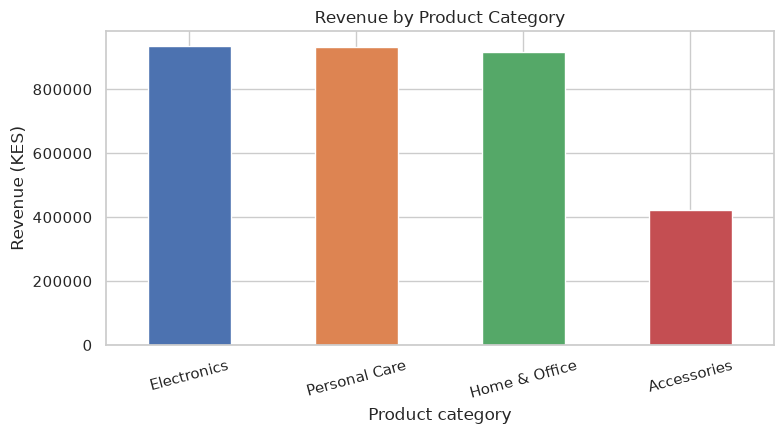

In [7]:
category_revenue = df.groupby('Category')['Revenue_KES'].sum().sort_values(ascending=False)
ax = category_revenue.plot.bar(figsize=(8,4.5), color=sns.color_palette('deep', len(category_revenue)))
ax.set(title='Revenue by Product Category', xlabel='Product category', ylabel='Revenue (KES)')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

**Interpretation:** Electronics leads at KES 934,500, narrowly ahead of Personal Care (KES 931,800). Revenue does not indicate margins or promotional lift.

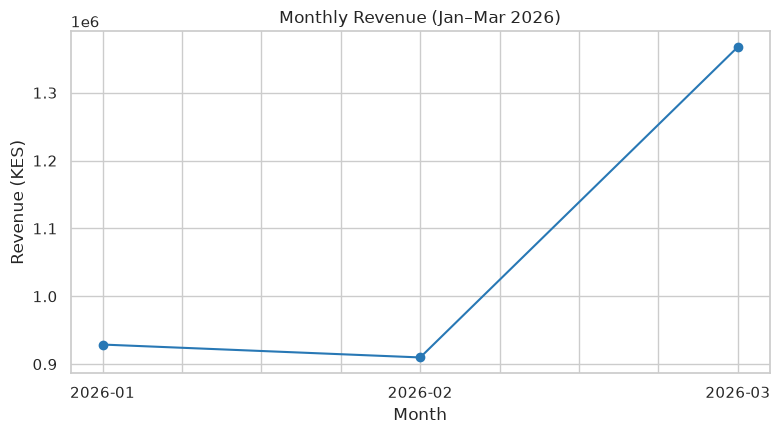

In [8]:
monthly_revenue = df.groupby(df['Date'].dt.to_period('M'))['Revenue_KES'].sum()
monthly_revenue.index = monthly_revenue.index.astype(str)
ax = monthly_revenue.plot(figsize=(8,4.5), marker='o', color='#2878B5')
ax.set(title='Monthly Revenue (Jan–Mar 2026)', xlabel='Month', ylabel='Revenue (KES)')
plt.tight_layout(); plt.show()

**Interpretation:** March is highest at KES 1,367,650 versus January KES 928,900 and February KES 909,900. Three months cannot establish a durable trend or its cause.

## One-page decision brief

**Business problem:** Provide a retail manager with a concise view of recent sales to guide category-level promotional planning.

**Stakeholder:** Retail manager.

**Decision supported:** Which category to investigate for a possible promotion, subject to margin, inventory, and campaign evidence. This descriptive analysis does not claim promotion impact.

**Unit of analysis:** One row is a sale/order line. `OrderID` is unique, giving 300 recorded rows/orders.

**KPIs:** Total revenue **KES 3,206,450**; distinct orders **300**; average revenue per order **KES 10,688.17**.

**Initial findings:** Electronics leads category revenue (KES 934,500), narrowly ahead of Personal Care (KES 931,800). March revenue is KES 1,367,650, compared with January's KES 928,900 and February's KES 909,900. These patterns warrant follow-up, but do not identify causes.

**Limitation:** Data span only January–March 2026 and omit margin/cost, stock, discount, demographic, and causal information. Revenue is not profit and cannot show that a promotion would generate incremental sales.


## Limitation and reproducibility
The data omit costs/margins, inventory, discounts, demographics and causal evidence, and cover only three months. No randomness is used. Run all cells top to bottom; dependencies are specified in `requirements.txt`.